# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import GeoNRWDataset
from aitlas.models import DeepLabV3
from aitlas.transforms import ResizeToTensor
import imageio

## Visualize images and masks

In [ ]:
dataset_config = {
    "data_dir": "./data/GeoNRW",
    "imagery": "all"
}
dataset = GeoNRWDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 7689


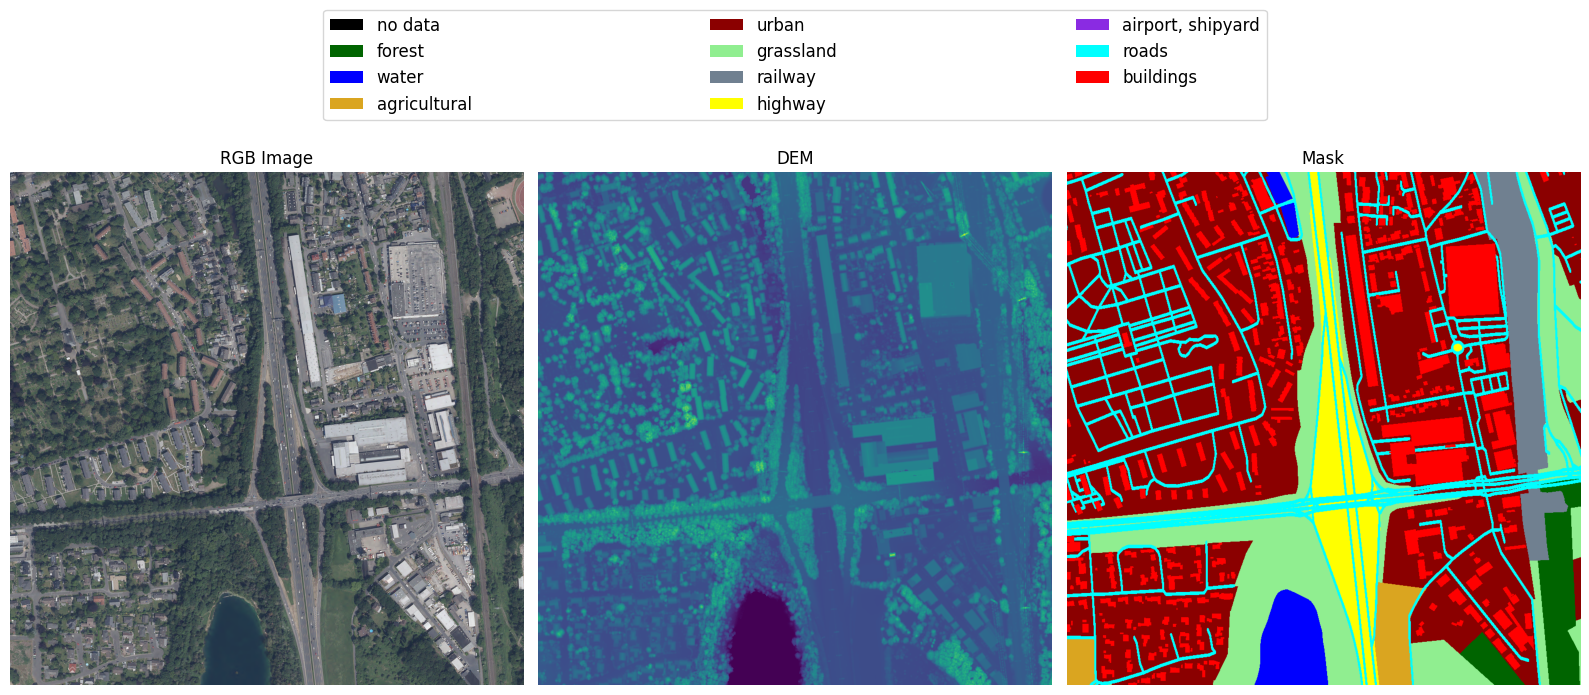

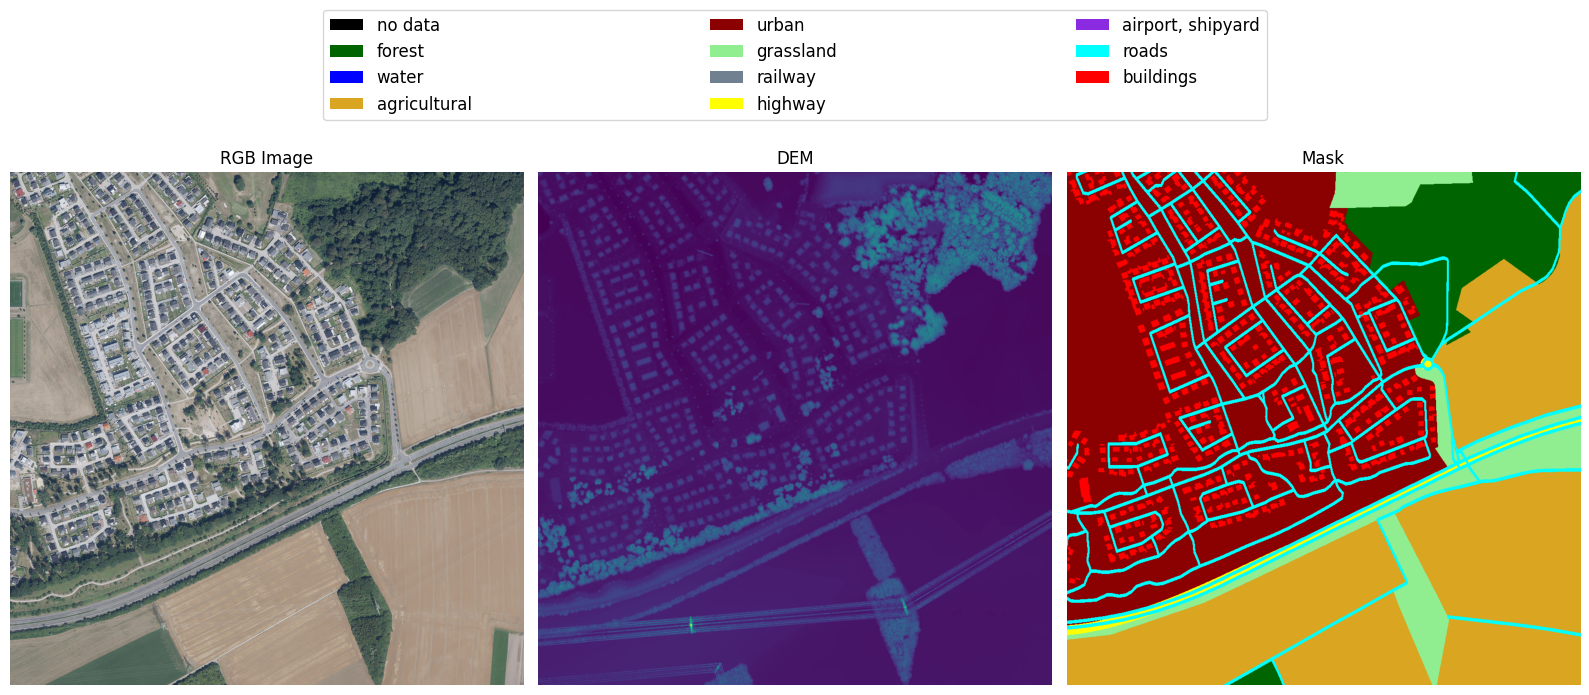

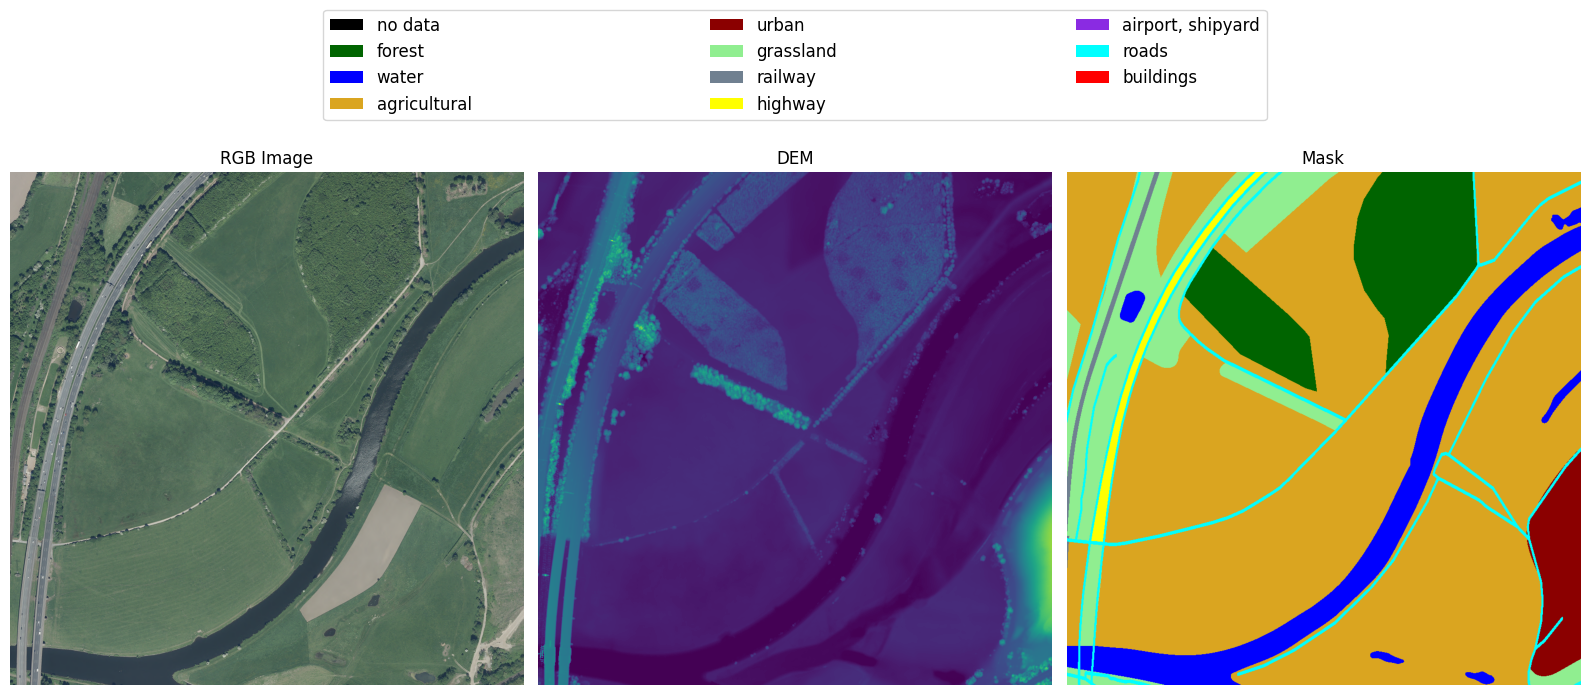

In [73]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(2040)
fig3 = dataset.show_image(7688)

In [19]:
dataset.data_distribution_table()

,Number of pixels
no data,1.460346e+08
forest,1.256436e+09
water,1.618676e+08
agricultural,2.802473e+09
urban,1.831696e+09
grassland,3.366986e+08
railway,4.273401e+07
highway,5.750586e+07
"airport, shipyard",3.477826e+07
roads,5.420532e+08


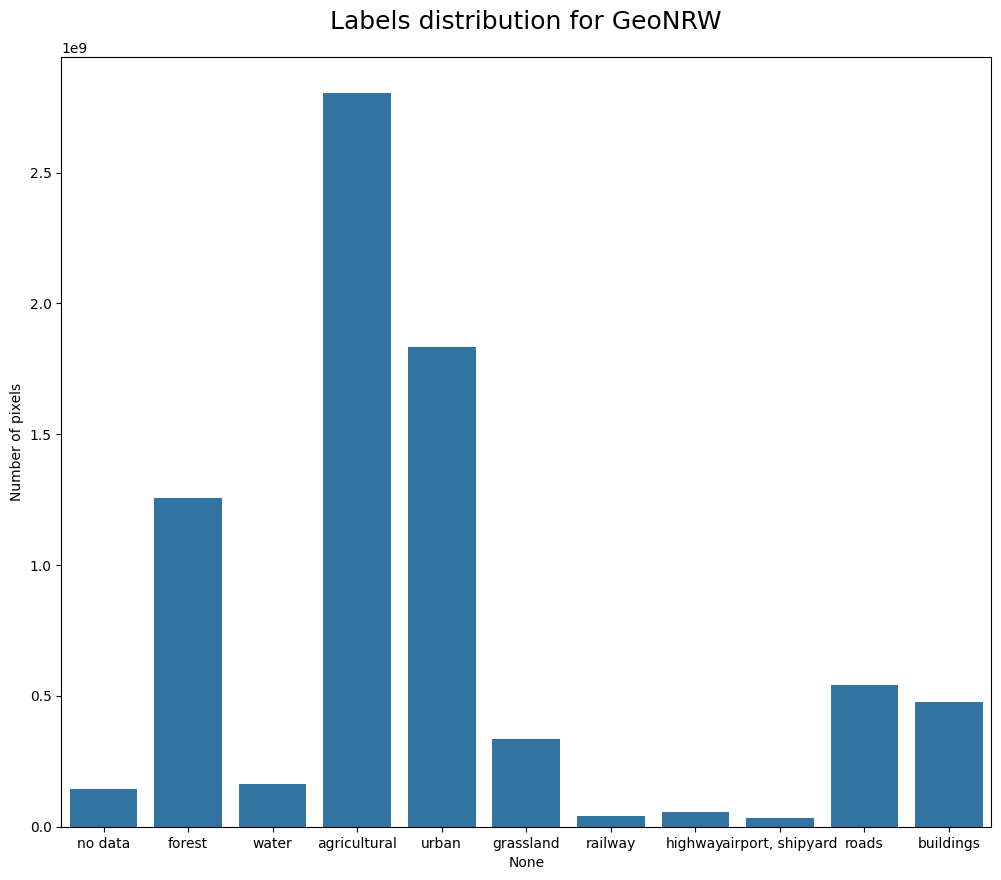

In [20]:
fig = dataset.data_distribution_barchart()

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 10,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/GeoNRW",
    "csv_file": "./data/GeoNRW/geonrw_train.csv",
    "imagery": "aerial", # can be replaced by dem or all
    "selection": "rgb",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = GeoNRWDataset(train_dataset_config)
len(train_dataset)

4623

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/experiments/GeoNRW/"
model_config = {
    "num_classes": 11, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2026-04-10 07:12:39,851 INFO Starting training.
training: 100%|██████████| 463/463 [08:46<00:00,  1.14s/it]
2026-04-10 07:21:26,170 INFO epoch: 1, time: 527, loss:  0.57134
testing on train set: 100%|██████████| 463/463 [09:29<00:00,  1.23s/it]
2026-04-10 07:30:58,014 INFO IOU:0.5407863790841607, IOU mean:0.24123614276001495, IOU per Class:[0.         0.68908453 0.66789733 0.76674676 0.32507691 0.
 0.         0.         0.         0.         0.20479204]
training: 100%|██████████| 463/463 [09:51<00:00,  1.28s/it]
2026-04-10 07:40:49,551 INFO epoch: 2, time: 591, loss:  0.31653
testing on train set: 100%|██████████| 463/463 [09:45<00:00,  1.26s/it]
2026-04-10 07:50:35,191 INFO IOU:0.5640382595206, IOU mean:0.24961717054764299, IOU per Class:[0.         0.70378295 0.65420972 0.78928505 0.34402646 0.
 0.         0.         0.         0.         0.25448469]
training: 100%|██████████| 463/463 [10:59<00:00,  1.42s/it]
2026-04-10 08:01:34,222 INFO epoch: 3, time: 659, loss:  0.27643
testing on

0.22529054290155506

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/GeoNRW",
    "csv_file": "./data/GeoNRW/geonrw_val.csv",
    "imagery": "aerial",
    "selection": "rgb",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = GeoNRWDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/GeoNRW/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

1539


2026-04-10 10:54:00,316 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/GeoNRW/checkpoint.pth.tar
2026-04-10 10:54:01,331 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/GeoNRW/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 385/385 [02:59<00:00,  2.14it/s]


[{'IOU': 0.577793264097602,
  'IOU mean': 0.2676659917767266,
  'IOU per Class': array([0.        , 0.7022338 , 0.77522892, 0.80831006, 0.34503083,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.31352229])}]


## Predictions

2026-04-10 10:57:01,102 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/GeoNRW/checkpoint.pth.tar
2026-04-10 10:57:01,948 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/GeoNRW/checkpoint.pth.tar at epoch 11


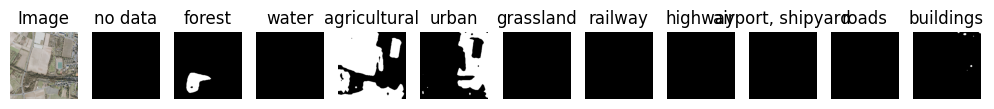

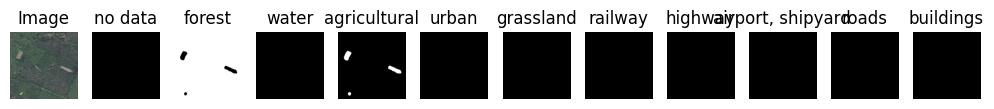

In [ ]:
model_path = "./data/experiments/GeoNRW/checkpoint.pth.tar"
labels = ["no data", "forest", "water", "agricultural", "urban", "grassland", "railway", "highway", "airport, shipyard", "roads", "buildings"]
transform = ResizeToTensor()
model.load_model(model_path)

image = imageio.imread("./data/GeoNRW/bonn/361_5622_rgb.jp2")
# image shape (H, W, 4)
if image.shape[2] == 4:
    image = image[:, :, :3]
fig = model.predict_masks(image, labels, transform)

image = imageio.imread("./data/GeoNRW/kleve/297_5736_rgb.jp2")
if image.shape[2] == 4:
    image = image[:, :, :3]  
fig = model.predict_masks(image, labels, transform)